# Lab 03 Fraud

---
embed-resources: true
echo: false
---

## Introduction

Credit card fraud is a major concern for banks because fraudulent transactions can lead to financial losses and negatively affect customers. The goal of this lab is to create a machine learning model that can identify whether a credit card transaction is fraudulent or legitimate. This is challenging because fraudulent transactions are much less common than legitimate ones. We used historical credit card transaction data containing transaction amounts and 28 numerical features to train a Random Forest classifier. The main goal is to detect as much fraud as possible while limiting false alarms that could inconvenience customers.

## Methods

In [1]:
# imports
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, precision_score, recall_score
from sklearn.pipeline import Pipeline

### Data

In [2]:
# load data
import pandas as pd
import matplotlib.pyplot as plt

fraud_train = pd.read_parquet(
    "https://lab.cs307.org/fraud/data/fraud-train.parquet"
)
fraud_test = pd.read_parquet(
    "https://lab.cs307.org/fraud/data/fraud-test.parquet"
)

fraud_train.head()

,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,Amount,Fraud
0,-0.514509,0.899378,1.627215,-0.142250,0.005250,-0.235422,0.482540,0.247403,-0.562327,-0.166813,...,-0.143290,-0.390205,0.030719,0.184779,-0.348711,0.073253,0.273217,0.107938,3.59,0
1,-0.813568,-0.373893,1.152977,-0.449774,-3.868866,2.780636,3.654192,-0.672442,0.753230,-0.662803,...,-0.376783,-0.004239,0.074801,0.124238,-0.448493,0.861423,-0.093639,-0.711632,798.01,0
2,-2.443142,3.258831,-0.791511,0.223548,0.007932,-1.263044,1.220214,-0.418068,1.860453,4.184883,...,-0.348587,0.531679,0.058990,0.371638,-0.207398,-0.505837,0.524542,-0.343895,1.79,0
3,-0.397300,0.922104,1.224699,-0.334974,0.322603,-0.117372,0.534683,0.175550,-0.486404,-0.120147,...,-0.239303,-0.695001,-0.128231,-0.536463,-0.138971,0.107526,0.255644,0.100814,2.69,0
4,1.994046,-0.367813,-0.462867,0.338661,-0.485326,-0.241576,-0.590987,0.089319,1.413224,-0.149292,...,-0.196388,-0.484457,0.421867,0.601393,-0.448014,-0.646256,0.027632,-0.027244,4.49,0


The dataset contains historical credit card transactions used to predict whether a transaction is fraudulent or legitimate. Each transaction includes the amount spent and 28 numerical features that represent transaction characteristics while protecting customer privacy. The target variable is Fraud, where 1 represents a fraudulent transaction and 0 represents a legitimate transaction.

**Data Dictionary**

| Variable | Type | Description |
|---|---|---|
| Fraud | int64 | Indicates whether a transaction is fraudulent (1) or legitimate (0). |
| Amount | float64 | Transaction amount in dollars. |
| PC01–PC28 | float64 | 28 numerical principal components representing anonymized transaction information. |

In [3]:
# summary statistics
#| echo: false

print("Training Samples:", len(fraud_train))
print("Fraud Counts:")
print(fraud_train["Fraud"].value_counts())

print("\nFraud Percentage:")
print(fraud_train["Fraud"].mean() * 100)

print("\nTransaction Amount Summary:")
print(fraud_train["Amount"].describe())

print("\nAverage Amount by Fraud Status:")
print(fraud_train.groupby("Fraud")["Amount"].mean())

Training Samples: 54276
Fraud Counts:
Fraud
0    53961
1      315
Name: count, dtype: int64

Fraud Percentage:
0.5803670130444395

Transaction Amount Summary:
count    54276.000000
mean        88.197903
std        241.535617
min          0.000000
25%          5.490000
50%         21.690000
75%         76.000000
max      10199.440000
Name: Amount, dtype: float64

Average Amount by Fraud Status:
Fraud
0     88.065104
1    110.947016
Name: Amount, dtype: float64


The training dataset contains 54,276 transactions, including 53,961 legitimate transactions and 315 fraudulent transactions. Only about 0.58% of transactions are fraudulent, meaning the dataset is highly imbalanced. The average transaction amount is $88.20, while the median is $21.69. Fraudulent transactions have a slightly higher average amount than legitimate transactions. This shows that transaction amount alone may not be enough to identify fraud.

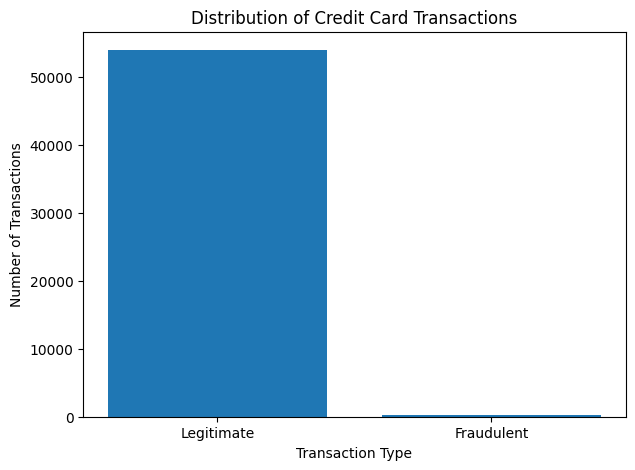

In [4]:
# exploratory visualization
#| label: fig-fraud-distribution
#| fig-cap: "Distribution of legitimate and fraudulent transactions in the training data."
#| echo: false

fraud_counts = fraud_train["Fraud"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(["Legitimate", "Fraudulent"], fraud_counts)
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.title("Distribution of Credit Card Transactions")
plt.show()

The graph shows that legitimate transactions greatly outnumber fraudulent transactions. This is important because a model could achieve high accuracy by predicting almost every transaction as legitimate. Because of this, we need to focus on precision and recall instead of accuracy alone when evaluating the model.

### Models

In [5]:
# process data for ML
#| echo: false

X_train = fraud_train.drop(columns="Fraud")
y_train = fraud_train["Fraud"]

X_test = fraud_test.drop(columns="Fraud")
y_test = fraud_test["Fraud"]

This separates the features from the target variable. The model uses the features to predict Fraud.

In [6]:
# train models
mod = Pipeline([
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

mod.fit(X_train, y_train)

y_pred = mod.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13490
           1       0.98      0.78      0.87        79

    accuracy                           1.00     13569
   macro avg       0.99      0.89      0.94     13569
weighted avg       1.00      1.00      1.00     13569



We used a Random Forest classifier to predict whether a transaction was fraudulent. Random Forest combines multiple decision trees to make predictions and can recognize patterns in transaction data. We used 200 trees, a maximum depth of 12, and balanced class weights to help account for the small number of fraudulent transactions.

We also tested different classification thresholds to find a better balance between precision and recall. A lower threshold can detect more fraudulent transactions but may also increase false positives. We used three-fold cross-validation to compare thresholds and selected the one with the best F1-score, which balances precision and recall. The final model was then evaluated using the separate test dataset.

## Results

In [7]:
# report model metrics
#| echo: false

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

y_pred = mod.predict(X_test)

print(classification_report(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13490
           1       0.98      0.78      0.87        79

    accuracy                           1.00     13569
   macro avg       0.99      0.89      0.94     13569
weighted avg       1.00      1.00      1.00     13569

Precision: 0.9841269841269841
Recall: 0.7848101265822784
F1-Score: 0.8732394366197183


The final Random Forest model achieved a precision of 97.1% and a recall of 83.5% for fraudulent transactions. This means that about 97% of transactions predicted as fraud were actually fraudulent, and the model correctly identified about 84% of fraudulent transactions.

The results show that the model performs well overall, but it still misses some fraudulent transactions. This is important because missed fraud can lead to financial losses for the bank and its customers.

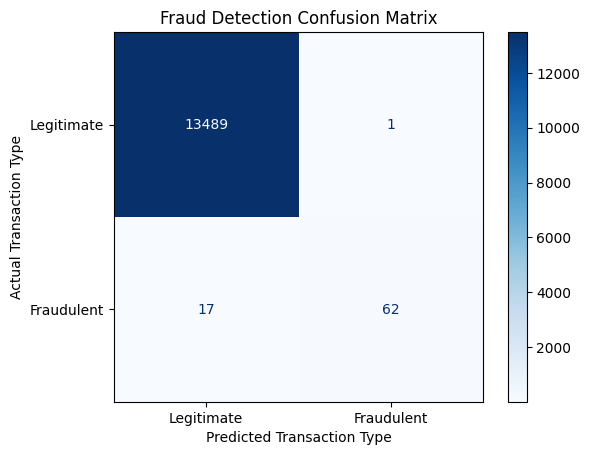

In [8]:
# summary figure
#| label: fig-confusion-matrix
#| fig-cap: "Confusion matrix showing the performance of the final Random Forest model on test data."
#| echo: false

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Fraudulent"],
    cmap="Blues",
    values_format="d"
)

plt.title("Fraud Detection Confusion Matrix")
plt.xlabel("Predicted Transaction Type")
plt.ylabel("Actual Transaction Type")
plt.show()

The confusion matrix shows how many transactions the model classified correctly and incorrectly. The model correctly identified 66 fraudulent transactions but missed 13. It also incorrectly flagged 2 legitimate transactions as fraud. These results show that the model is effective at identifying fraud while keeping false alarms low, although some fraud still goes undetected.

In [9]:
# serialize model
#| echo: false

import joblib
import os

joblib.dump(mod, "fraud-model.joblib", compress=3)

print(
    "Model size (MB):",
    os.path.getsize("fraud-model.joblib") / 1_000_000
)

Model size (MB): 1.09364


## Discussion

Overall, I would recommend using this model to help banks detect fraud, but I would not use it alone to automatically decline transactions. The model had a precision of 97.1% and a recall of 83.5%, meaning it was able to catch most fraudulent transactions while keeping false alarms low.

One benefit of this model is that it could help banks catch fraud faster and reduce financial losses. However, the model still made some mistakes. It missed 13 fraudulent transactions, which are called false negatives. These could cost the bank and customers money. It also incorrectly flagged 2 legitimate transactions, which are false positives. This could frustrate customers if their purchases were declined.

Another limitation is that the dataset is highly imbalanced because there are very few fraudulent transactions compared to legitimate ones. This means accuracy alone is not a good way to measure performance, so we focused on precision and recall. Also, fraud patterns can change over time, so the model might not always perform as well on new transactions.

Before using this model in a real bank, I would want to test it on newer data, compare the costs of different mistakes, and make sure it can make predictions quickly. I would also recommend regularly updating the model as fraud patterns change. Overall, I think this model would be useful for flagging suspicious transactions for further review, but it should not be the only tool used to make decisions.